In [6]:
#data presentation donut chart

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import plotly.graph_objects as go

%run ../../docs/plotly_theme.ipynb



In [8]:
CLEANED_CSV_DIR = r"C:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned"
SAVING_PATH = r"C:\Users\hanna\ADA\ada-2025-project-json-derulo\docs\plots"

In [9]:
def plot_funny_categories_donut(data_path):
    """
    Load all CSV files in data_path and plot a donut chart
    comparing 'not_funny', 'somewhat_funny', and 'funny' votes
    (with percentages).

    Parameters
    ----------
    data_path : str or Path
        Path to the directory containing cleaned CSV files.
    """
    data_path = Path(data_path)

    # Read all CSV files
    dfs = [pd.read_csv(f) for f in data_path.glob("*.csv")]
    if not dfs:
        raise ValueError("No CSV files found in the specified directory.")

    data = pd.concat(dfs, ignore_index=True)

    # Sum votes
    not_funny = data["not_funny"].sum()
    somewhat_funny = data["somewhat_funny"].sum()
    funny = data["funny"].sum()
    total = not_funny + somewhat_funny + funny

    # Prepare plot data
    sizes = [not_funny, somewhat_funny, funny]
    labels = [
        f"Not funny\n{not_funny} ({not_funny / total * 100:.1f}%)",
        f"Somewhat funny\n{somewhat_funny} ({somewhat_funny / total * 100:.1f}%)",
        f"Funny\n{funny} ({funny / total * 100:.1f}%)"
    ]

    # Donut plot
    fig, ax = plt.subplots()
    ax.pie(
        sizes,
        labels=labels,
        startangle=90,
        wedgeprops=dict(width=0.4)
    )
    ax.set_aspect("equal")

    plt.title("Caption Funniest Categories Distribution")
    plt.show()


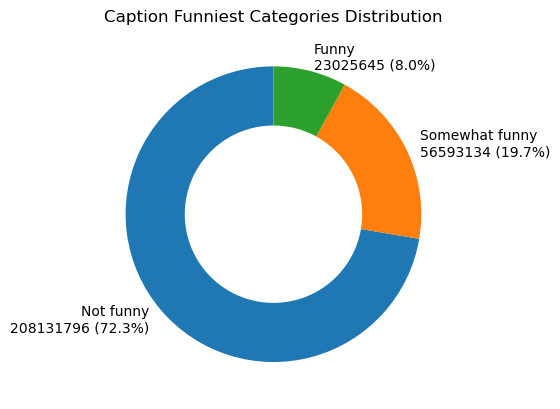

In [10]:
plot_funny_categories_donut(CLEANED_CSV_DIR)

In [11]:
def plot_funny_categories_donut_plotly(data_path, output_dir):
    """
    Create a Plotly donut chart for not_funny / somewhat_funny / funny votes
    and save it as a standalone HTML file.

    Parameters
    ----------
    data_path : str or Path
        Directory containing cleaned CSV files
    output_dir : str or Path
        Directory where the HTML plot will be saved
    """
    data_path = Path(data_path)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # Load data
    dfs = [pd.read_csv(f) for f in data_path.glob("*.csv")]
    if not dfs:
        raise ValueError("No CSV files found in the specified directory.")

    data = pd.concat(dfs, ignore_index=True)

    # Aggregate votes
    values = [
        data["not_funny"].sum(),
        data["somewhat_funny"].sum(),
        data["funny"].sum()
    ]

    labels = ["Unfunny", "Somewhat Funny", "Funny"]

    total = sum(values)
    percentages = [v / total * 100 for v in values]

    hover_text = [
        f"{label}<br>{v:,} votes<br>{p:.1f}%"
        for label, v, p in zip(labels, values, percentages)
    ]

    # Create donut chart
    fig = go.Figure(
        data=[
            go.Pie(
                labels=labels,
                values=values,
                hole=0.6,
                hovertext=hover_text,
                hoverinfo="text",
                textinfo="label+percent"
            )
        ]
    )

    fig.update_layout(
        title="Caption Funniest Categories Distribution",
        showlegend=True,
        margin=dict(t=60, b=40, l=40, r=40)
    )

    # Save plot
    output_path = output_dir / "funny_categories_donut.html"
    fig.write_html(output_path, include_plotlyjs="cdn")

    return output_path

In [12]:
plot_funny_categories_donut_plotly(CLEANED_CSV_DIR, SAVING_PATH)

WindowsPath('C:/Users/hanna/ADA/ada-2025-project-json-derulo/docs/plots/funny_categories_donut.html')